# Лабораторная работа 8
## Свёрточная сеть на CIFAR-10

60 000 цветных картинок 32×32, 10 классов. Пиксели приводятся к диапазону от 0 до 1, метка класса разворачивается в one-hot.

Свёртка скользит окном 3×3 и ищет локальный узор. MaxPool оставляет максимум в клетке 2×2. Softmax превращает 10 чисел в вероятности. Потеря — categorical cross-entropy: минус логарифм вероятности верного класса.

Ниже сначала формулы Adam, AdamW и AMSGrad, затем две сети на CIFAR-10.


## Оптимизаторы Adam, AdamW и AMSGrad


In [1]:
# -*- coding: utf-8 -*-
"""Ручные оптимизаторы для части 2 лабораторной 8: Adam, AdamW, AMSGrad."""

import numpy as np


class _AdamBase:
    def __init__(self, lr=0.05, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self.m = None
        self.v = None

    def _moments(self, grad):
        if self.m is None:
            self.m = np.zeros_like(grad)
            self.v = np.zeros_like(grad)
        self.t += 1
        self.m = self.beta1 * self.m + (1.0 - self.beta1) * grad
        self.v = self.beta2 * self.v + (1.0 - self.beta2) * (grad ** 2)
        m_hat = self.m / (1.0 - self.beta1 ** self.t)
        v_hat = self.v / (1.0 - self.beta2 ** self.t)
        return m_hat, v_hat


class Adam(_AdamBase):
    """Adam: шаг делится на корень скользящего среднего квадратов градиента.

    m гасит дрожание направления, v не даёт большому градиенту сделать огромный шаг.
    Поправка (1 - beta^t) снимает смещение первых шагов, когда средние ещё около нуля.
    """

    def step(self, weights, grad):
        m_hat, v_hat = self._moments(grad)
        return weights - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


class AdamW(_AdamBase):
    """AdamW: затухание весов вычитается отдельно от адаптивного шага.

    В обычном Adam штраф weight decay попадает внутрь градиента и тоже делится
    на корень v. У AdamW штраф всегда равен lr * decay * w, без этого деления.
    """

    def __init__(self, lr=0.05, beta1=0.9, beta2=0.999, eps=1e-8, weight_decay=0.01):
        super().__init__(lr, beta1, beta2, eps)
        self.weight_decay = weight_decay

    def step(self, weights, grad):
        m_hat, v_hat = self._moments(grad)
        adapted = m_hat / (np.sqrt(v_hat) + self.eps)
        return weights - self.lr * (adapted + self.weight_decay * weights)


class AMSGrad(_AdamBase):
    """AMSGrad помнит наибольшую оценку второго момента и не даёт шагу снова вырасти.

    У Adam знаменатель sqrt(v_hat) иногда уменьшается, и шаг внезапно становится
    длиннее. AMSGrad держит v_max = max(v_max, v_hat) и делит только на него.
    """

    def __init__(self, lr=0.05, beta1=0.9, beta2=0.999, eps=1e-8):
        super().__init__(lr, beta1, beta2, eps)
        self.v_max = None

    def step(self, weights, grad):
        m_hat, v_hat = self._moments(grad)
        if self.v_max is None:
            self.v_max = v_hat.copy()
        else:
            self.v_max = np.maximum(self.v_max, v_hat)
        return weights - self.lr * m_hat / (np.sqrt(self.v_max) + self.eps)


def quadratic_loss_and_grad(weights, target):
    """Выпуклая функция 0.5 * ||w - target||^2. Минимум в точке target, градиент w - target."""
    diff = weights - target
    loss = 0.5 * float(np.sum(diff ** 2))
    return loss, diff


def run_optimizer(optimizer, steps=50, dimension=5, seed=0):
    """Пятьдесят шагов к известной точке. Возвращает потери и нормы весов."""
    rng = np.random.default_rng(seed)
    target = rng.normal(size=dimension)
    weights = np.zeros(dimension)
    losses = []
    norms = []
    for _ in range(steps):
        loss, grad = quadratic_loss_and_grad(weights, target)
        losses.append(loss)
        norms.append(float(np.linalg.norm(weights)))
        weights = optimizer.step(weights, grad)
    return np.asarray(losses), np.asarray(norms), weights, target


In [2]:
%matplotlib inline
# -*- coding: utf-8 -*-
"""
Лабораторная работа 8 — свёрточная сеть на CIFAR-10 и сравнение оптимизаторов.

Запуск: python lab8/lab8.py
Графики: lab8/figures/
Данные CIFAR-10 скачиваются в lab8/data.
"""

from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from optimizers import AMSGrad, Adam, AdamW, run_optimizer

ROOT = Path.cwd()
if not (ROOT / 'lab8.py').exists() and (ROOT / 'lab8').is_dir():
    ROOT = ROOT / 'lab8'
DATA = ROOT / "data"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

CLASSES = [
    "самолёт",
    "автомобиль",
    "птица",
    "кошка",
    "олень",
    "собака",
    "лягушка",
    "лошадь",
    "корабль",
    "грузовик",
]
CLASS_EN = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]


def categorical_crossentropy(probabilities, one_hot):
    """Среднее -sum y log p. Вероятности уже после softmax."""
    clipped = probabilities.clamp(min=1e-8)
    return -(one_hot * clipped.log()).sum(dim=1).mean()


class SmallCNN(nn.Module):
    """Два свёрточных блока, полносвязный слой, Dropout и softmax на 10 классов."""

    def __init__(self, channels=(32, 64), dropout=0.3, batch_norm=False):
        super().__init__()
        blocks = []
        in_channels = 3
        for out_channels in channels:
            blocks.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
            if batch_norm:
                blocks.append(nn.BatchNorm2d(out_channels))
            blocks.append(nn.ReLU())
            blocks.append(nn.MaxPool2d(2))
            in_channels = out_channels
        self.features = nn.Sequential(*blocks)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels[-1] * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, images):
        logits = self.classifier(self.features(images))
        return torch.softmax(logits, dim=1)

    def first_conv(self):
        return self.features[0]


def load_cifar(batch_size=128):
    transform = transforms.ToTensor()
    train = datasets.CIFAR10(DATA, train=True, download=True, transform=transform)
    test = datasets.CIFAR10(DATA, train=False, download=True, transform=transform)
    train_loader = DataLoader(train, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test, batch_size=batch_size, shuffle=False)
    return train_loader, test_loader


def epoch_pass(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_correct = 0
    total = 0
    grad_mode = torch.enable_grad() if training else torch.no_grad()
    with grad_mode:
        for images, labels in loader:
            one_hot = torch.nn.functional.one_hot(labels, num_classes=10).float()
            probabilities = model(images)
            loss = categorical_crossentropy(probabilities, one_hot)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            predicted = probabilities.argmax(dim=1)
            total_loss += float(loss.detach()) * len(labels)
            total_correct += int((predicted == labels).sum())
            total += len(labels)
    return total_loss / total, total_correct / total


def train_model(model, train_loader, test_loader, epochs=10, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = epoch_pass(model, train_loader, optimizer)
        test_loss, test_acc = epoch_pass(model, test_loader)
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "train_acc": train_acc,
                "test_loss": test_loss,
                "test_acc": test_acc,
            }
        )
        print(
            f"  эпоха {epoch:02d}  train acc={train_acc:.3f}  test acc={test_acc:.3f}  "
            f"test loss={test_loss:.3f}"
        )
    return history


def predict_all(model, loader):
    model.eval()
    true_labels = []
    pred_labels = []
    images_kept = []
    kept = 0
    with torch.no_grad():
        for images, labels in loader:
            probabilities = model(images)
            true_labels.append(labels.numpy())
            pred_labels.append(probabilities.argmax(dim=1).numpy())
            if kept < 12:
                piece = images[: 12 - kept]
                images_kept.append(piece)
                kept += len(piece)
    return (
        np.concatenate(true_labels),
        np.concatenate(pred_labels),
        torch.cat(images_kept, dim=0),
    )


def plot_history(histories, path):
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, history in histories.items():
        epochs = [row["epoch"] for row in history]
        ax.plot(epochs, [row["test_acc"] for row in history], marker="o", label=name)
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Accuracy на тесте")
    ax.set_title("Базовая и улучшенная сети")
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_confusion(y_true, y_pred, path):
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        display_labels=CLASS_EN,
        xticks_rotation=45,
        ax=ax,
        colorbar=False,
    )
    ax.set_title("Матрица ошибок улучшенной сети")
    fig.tight_layout()
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_examples(images, y_true, y_pred, path):
    fig, axes = plt.subplots(3, 4, figsize=(10, 7))
    for ax, image, true_i, pred_i in zip(axes.ravel(), images, y_true, y_pred):
        picture = image.permute(1, 2, 0).numpy()
        ax.imshow(picture)
        mark = "верно" if true_i == pred_i else "ошибка"
        ax.set_title(f"{CLASS_EN[true_i]} → {CLASS_EN[pred_i]}\n{mark}", fontsize=8)
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_filters(model, path):
    weight = model.first_conv().weight.detach().cpu()
    count = min(16, weight.shape[0])
    fig, axes = plt.subplots(4, 4, figsize=(6, 6))
    for ax, filt in zip(axes.ravel(), weight[:count]):
        image = filt.permute(1, 2, 0).numpy()
        image = image - image.min()
        image = image / max(image.max(), 1e-8)
        ax.imshow(image)
        ax.axis("off")
    fig.suptitle("Фильтры первого свёрточного слоя")
    fig.tight_layout()
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


def compare_optimizers(path):
    runs = {
        "Adam": Adam(lr=0.1),
        "AdamW": AdamW(lr=0.1, weight_decay=0.01),
        "AMSGrad": AMSGrad(lr=0.1),
    }
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for name, optimizer in runs.items():
        losses, norms, _weights, _target = run_optimizer(optimizer, steps=50, seed=0)
        axes[0].plot(losses, label=name)
        axes[1].plot(norms, label=name)
        print(f"  {name:8s} потеря 0→{losses[0]:.3f}, 49→{losses[-1]:.4f}")
    axes[0].set_title("Потеря за 50 шагов")
    axes[0].set_xlabel("Шаг")
    axes[0].set_ylabel("0.5 ||w - цель||²")
    axes[0].legend()
    axes[1].set_title("Норма весов")
    axes[1].set_xlabel("Шаг")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


In [3]:
torch.manual_seed(42)
np.random.seed(42)


## 1. CIFAR-10


In [4]:
train_loader, test_loader = load_cifar(batch_size=128)
images, labels = next(iter(train_loader))
print("Батч:", tuple(images.shape), "пиксели", float(images.min()), float(images.max()))
print("Классы:", CLASS_EN)


Батч: (128, 3, 32, 32) пиксели 0.0 1.0
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 2. Базовая сеть, 10 эпох, Adam


In [5]:
base = SmallCNN(channels=(32, 64), dropout=0.3, batch_norm=False)
base_history = train_model(base, train_loader, test_loader, epochs=10, lr=1e-3)


  эпоха 01  train acc=0.405  test acc=0.522  test loss=1.345


  эпоха 02  train acc=0.531  test acc=0.592  test loss=1.144


  эпоха 03  train acc=0.584  test acc=0.630  test loss=1.050


  эпоха 04  train acc=0.616  test acc=0.655  test loss=0.999


  эпоха 05  train acc=0.646  test acc=0.672  test loss=0.929


  эпоха 06  train acc=0.665  test acc=0.677  test loss=0.921


  эпоха 07  train acc=0.682  test acc=0.693  test loss=0.889


  эпоха 08  train acc=0.698  test acc=0.694  test loss=0.884


  эпоха 09  train acc=0.710  test acc=0.702  test loss=0.860


  эпоха 10  train acc=0.725  test acc=0.708  test loss=0.850


## 3. Улучшенная сеть: BatchNorm, больше фильтров, Dropout 0.5


  эпоха 01  train acc=0.359  test acc=0.479  test loss=1.527


  эпоха 02  train acc=0.443  test acc=0.559  test loss=1.231


  эпоха 03  train acc=0.474  test acc=0.599  test loss=1.158


  эпоха 04  train acc=0.495  test acc=0.576  test loss=1.164


  эпоха 05  train acc=0.513  test acc=0.620  test loss=1.078


  эпоха 06  train acc=0.525  test acc=0.622  test loss=1.079


  эпоха 07  train acc=0.535  test acc=0.555  test loss=1.265


  эпоха 08  train acc=0.548  test acc=0.537  test loss=1.408


  эпоха 09  train acc=0.556  test acc=0.661  test loss=0.988


  эпоха 10  train acc=0.567  test acc=0.646  test loss=1.033


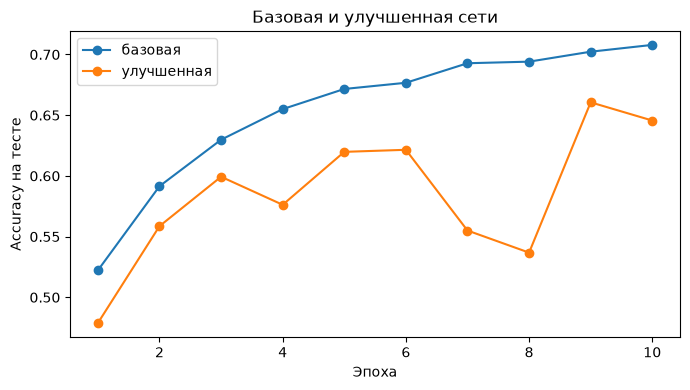


Тест улучшенной сети: accuracy=0.6456


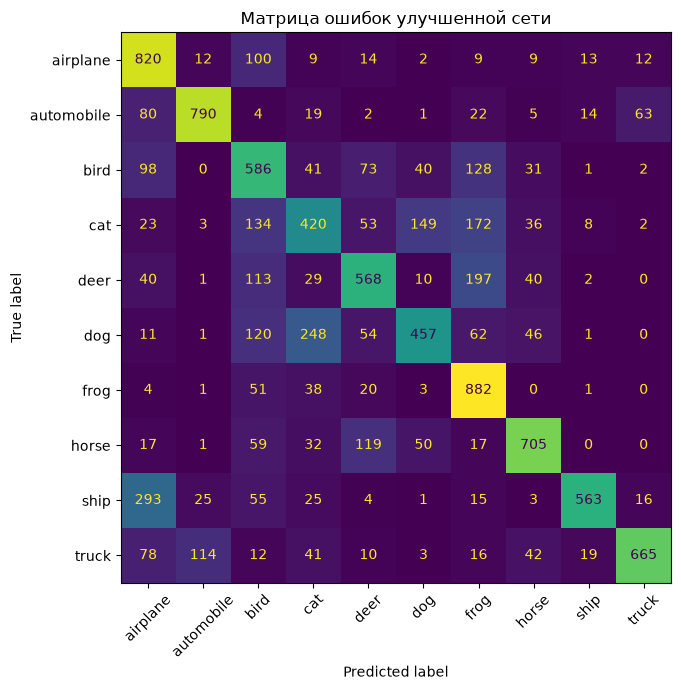

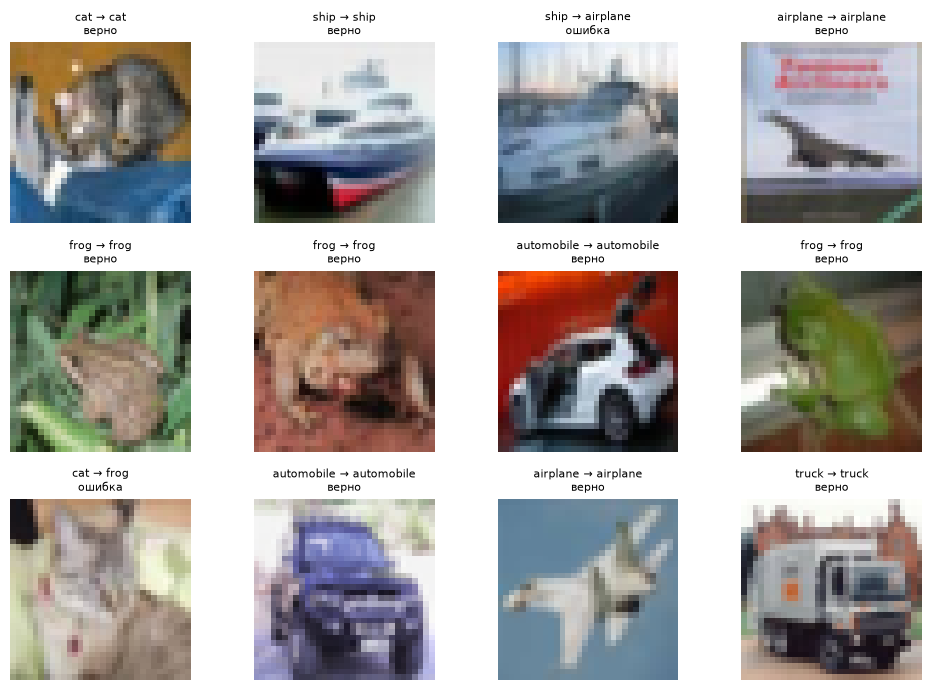

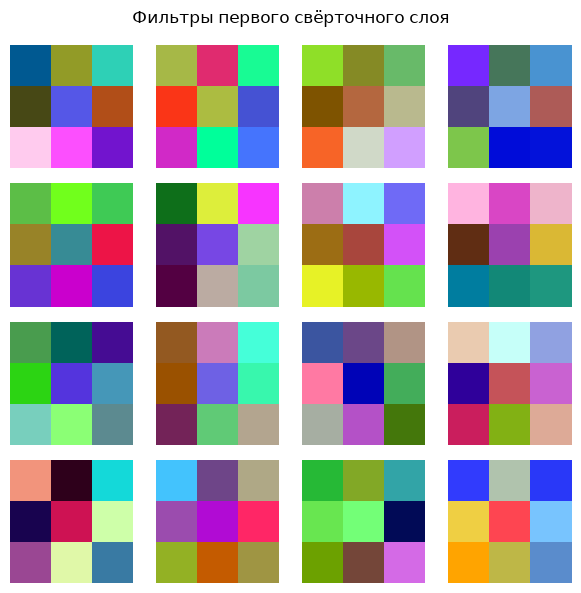

In [6]:
better = SmallCNN(channels=(64, 128), dropout=0.5, batch_norm=True)
better_history = train_model(better, train_loader, test_loader, epochs=10, lr=1e-3)
plot_history(
    {"базовая": base_history, "улучшенная": better_history},
    FIG / "01_accuracy.png",
)

y_true, y_pred, preview = predict_all(better, test_loader)
print(f"\nТест улучшенной сети: accuracy={accuracy_score(y_true, y_pred):.4f}")
plot_confusion(y_true, y_pred, FIG / "02_confusion.png")
plot_examples(preview, y_true[:12], y_pred[:12], FIG / "03_examples.png")
plot_filters(better, FIG / "04_filters.png")


## 4. Adam, AdamW и AMSGrad, 50 шагов


  Adam     потеря 0→0.371, 49→0.0005
  AdamW    потеря 0→0.371, 49→0.0005
  AMSGrad  потеря 0→0.371, 49→0.0005


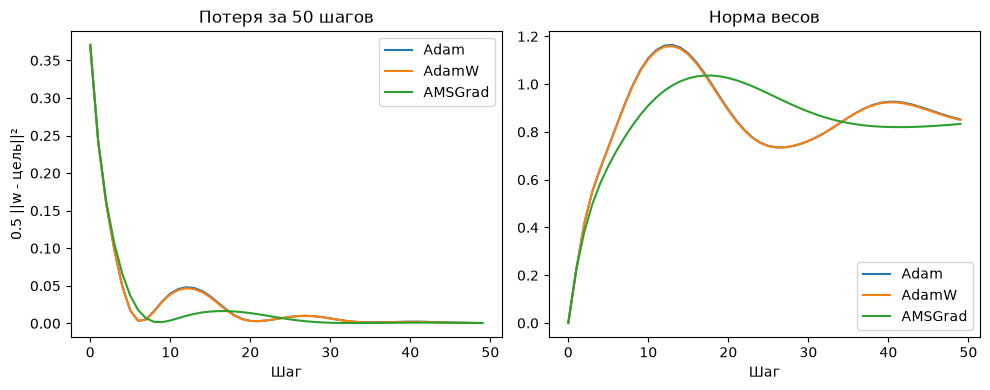


Графики: C:\WORK\MMO\lab8\figures


In [7]:
compare_optimizers(FIG / "05_optimizers.png")
print(f"\nГрафики: {FIG}")


## Выводы

Базовая сеть за 10 эпох доходит примерно до точности 0.71 на тесте. Более широкая сеть с BatchNorm и Dropout 0.5 за те же 10 эпох остаётся ниже: обучение не успевает, это недообучение, а не переобучение. На гладкой параболе Adam, AdamW и AMSGrad за 50 шагов сходятся почти одинаково. AdamW чуть сильнее тянет веса к нулю, AMSGrad не даёт оценке второго момента уменьшиться.
